# Shipping equity research
## Star Bulk: assets, cash flows and implied freight rates

**Snapshot: 9 October 2026.** This walkthrough calculates from reviewed CSV/JSON inputs.
It does not read spreadsheet answers to produce valuations. Excel calculation evidence is
read only in the final reconciliation step.

The research question is whether dated fleet asset backing and sustainable cash generation
support the same conclusion. The output is conditional on disclosed assumptions;
the cash bridge, charter book and remaining newbuild payments are not fully observed.

Read the source notes before treating an output as an investment conclusion.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from shipping_equity.data import load_company
from shipping_equity.valuation import value_company, reverse_valuation
from shipping_equity.reconcile import reconcile

ROOT = Path.cwd()
if not (ROOT / 'data/companies').exists():
    ROOT = ROOT.parent
company = load_company(ROOT / 'data/companies/SBLK')
OUT = ROOT / 'outputs/sblk-2026-10-09'
print(company.metadata['name'], company.metadata['valuation_date'])
print('Input SHA-256:', company.fingerprint)

Star Bulk Carriers 2026-10-09
Input SHA-256: 98278536e987c1373aac529d7aa2cc20a45ce8d675b42e177f49c3780acdb328


## 1. Begin with the evidence

The October fleet register contains 135 operating vessels and three committed newbuilds.
The appraisal annexes use earlier effective dates; joining by individual vessel identity
excludes two sold ships. The appraisal's introductory vessel count conflicts with its rows.
The raw source IMO typo is retained, not silently corrected.

Source financial statements report USD thousands. Input CSVs convert them to USD exactly once.
Restricted cash is excluded from available cash. Completed share issuance and debt repayments
are bridged separately; unused ATM capacity is not treated as completed dilution.

In [2]:
display(pd.DataFrame(company.sources)[['id', 'published', 'title', 'url']])
display(company.fleet.groupby('vessel_class').agg(
    vessels=('vessel_id','count'), dwt=('dwt','sum'), appraisal_usd=('appraisal_usd','sum')))
f = company.facts
assert f['voyage_revenue'] - f['voyage_cost'] - f['charter_hire'] + f['realized_derivatives'] == f['tce_revenue']
assert f['opening_total_cash'] + f['cash_from_operations'] + f['cash_from_investing'] + f['cash_from_financing'] == f['closing_total_cash']
print('Historical TCE revenue and cash-flow bridges reconcile.')

,id,published,title,url
0,SBLK_INTERIM,2026-08-07,Star Bulk H1 2026 interim filing,https://www.sec.gov/Archives/edgar/data/138671...
1,SBLK_APPRAISAL,2026-09-04,Arrow fleet appraisal filed by Star Bulk,https://www.sec.gov/Archives/edgar/data/138671...
2,SBLK_PROSPECTUS,2026-10-09,Star Bulk October 9 prospectus supplement,https://www.sec.gov/Archives/edgar/data/138671...
3,SBLK_PRICE,2026-10-09,SBLK Nasdaq historical close,https://stockanalysis.com/stocks/sblk/history/
4,SBLK_PRICE_CHECK,2026-10-09,SBLK historical OHLC cross-check,https://chartexchange.com/symbol/nasdaq-sblk/h...


,vessels,dwt,appraisal_usd
vessel_class,,,
Capesize,14,2516415,510000000
Kamsarmax,42,3443437,1064750000
Newcastlemax,17,3535864,1141750000
Post Panamax,7,670632,148750000
Supramax,11,631163,163500000
Ultramax,47,2953041,1274750000


Historical TCE revenue and cash-flow bridges reconcile.


## 2. Make the scenarios explicit

TCE is time-charter-equivalent earnings in USD/day, applied to available vessel days.
Vessel costs accrue on ownership days. Off-hire is a fraction of those days.
The base model assumes open-market exposure; this is not a reconstructed charter book.
The rate vector is an editable scenario, not an FFA curve or a statistical forecast.

Corporate overhead scales with fleet activity, subject to a fixed-cost fraction while vessels
operate. Drydock cash uses a smoothed annual budget. Both rates and costs inflate at 2% in the
base scenario; changing this assumption requires economic judgment.

In [3]:
assumptions = pd.DataFrame(company.assumptions.values())
display(assumptions[['label','unit','bear','base','bull','rationale']])
cases = {case: value_company(company, case) for case in ['bear','base','bull']}
summary = pd.DataFrame({case: result.summary for case, result in cases.items()}).T
display(summary[['price','nav_per_share','dcf_per_share','price_nav','next_year_ufcf','next_year_equity_cash']].round(2))

,label,unit,bear,base,bull,rationale
0,Newcastlemax open TCE,USD/day,1.800000e+04,2.600000e+04,3.400000e+04,Illustrative class-rate range. No licensed cla...
1,Capesize open TCE,USD/day,1.600000e+04,2.400000e+04,3.200000e+04,Illustrative class-rate range. No licensed cla...
2,Post Panamax open TCE,USD/day,1.100000e+04,1.600000e+04,2.100000e+04,Illustrative class-rate range. No licensed cla...
3,Kamsarmax open TCE,USD/day,1.200000e+04,1.700000e+04,2.200000e+04,Illustrative class-rate range. No licensed cla...
4,Ultramax open TCE,USD/day,1.150000e+04,1.650000e+04,2.100000e+04,Illustrative class-rate range. No licensed cla...
5,Supramax open TCE,USD/day,1.050000e+04,1.450000e+04,1.900000e+04,Illustrative class-rate range. No licensed cla...
6,Discount rate,fraction,1.200000e-01,1.000000e-01,8.500000e-02,Nominal unlevered discount-rate scenarios; not...
7,Appraisal multiplier,multiple,8.000000e-01,1.000000e+00,1.150000e+00,"Scenario mark relative to dated appraisals, no..."
8,Retirement age,years,2.300000e+01,2.500000e+01,2.700000e+01,Retire July 1 of build year plus age; build mo...
9,Unavailable share of owned days,fraction,7.000000e-02,5.000000e-02,4.000000e-02,Includes normalized docking downtime. H1 discl...


,price,nav_per_share,dcf_per_share,price_nav,next_year_ufcf,next_year_equity_cash
bear,29.7,24.59,2.24,1.21,1.094973e+08,-9.637501e+07
base,29.7,32.99,26.55,0.90,4.425100e+08,2.495406e+08
bull,29.7,39.11,57.20,0.76,7.506717e+08,5.663041e+08


## 3. Two valuation lenses

Asset NAV adds unrestricted cash and operating working capital to fleet appraisals, then
subtracts gross debt, other claims and remaining committed delivery payments. Paid deposits
are not added again. This asset NAV excludes the present value of future corporate overhead.

The DCF forecasts twelve quarters and annual fleet runoff. Cash flows include maintenance,
delivery payments, working capital and scrap. Interest and principal belong in the separate
financing schedule; they are not deducted again in unlevered enterprise value.
There is no perpetual terminal value or unfinanced replacement fleet.

fleet_value        4.303500e+09
cash               5.211420e+08
debt               9.490720e+08
other_claims       0.000000e+00
remaining_capex    7.322100e+07
shares             1.160714e+08
equity_nav         3.828944e+09
nav_per_share      3.298784e+01
price_nav          9.003318e-01
Name: USD unless per-share/ratio, dtype: float64

,label,owned,available,revenue,operating,maintenance,newbuild,scrap,delta_wc,ufcf,pv
0,Q4:26 stub,11208.0,10647.6,1.966749e+08,1.029067e+08,4000996.94,73221000.0,0.0,16649781.07,8.051549e+06,7.878923e+06
1,Q1:27,12420.0,11799.0,2.186032e+08,1.142745e+08,4454508.74,0.0,0.0,1083093.34,1.076439e+08,1.028894e+08
2,Q2:27,12558.0,11930.1,2.221201e+08,1.161130e+08,4526172.17,0.0,0.0,218183.58,1.102580e+08,1.029133e+08
3,Q3:27,12696.0,12061.2,2.256785e+08,1.179731e+08,4598682.63,0.0,0.0,221686.24,1.120244e+08,1.020800e+08
4,Q4:27,12696.0,12061.2,2.268077e+08,1.185635e+08,4621693.63,0.0,0.0,224009.94,1.125837e+08,1.001545e+08
5,Q1:28,12558.0,11930.1,2.254589e+08,1.178583e+08,4594207.97,0.0,0.0,223904.27,1.119129e+08,9.721991e+07
6,Q2:28,12558.0,11930.1,2.265748e+08,1.184417e+08,4616946.09,0.0,0.0,223785.90,1.124681e+08,9.540789e+07
7,Q3:28,12696.0,12061.2,2.302046e+08,1.203391e+08,4690910.77,0.0,0.0,226132.23,1.142711e+08,9.463639e+07
8,Q4:28,12696.0,12061.2,2.313565e+08,1.209413e+08,4714383.27,0.0,0.0,228502.54,1.148416e+08,9.285129e+07
9,Q1:29,12420.0,11799.0,2.274471e+08,1.188977e+08,4634722.34,0.0,0.0,227143.61,1.128986e+08,8.916014e+07


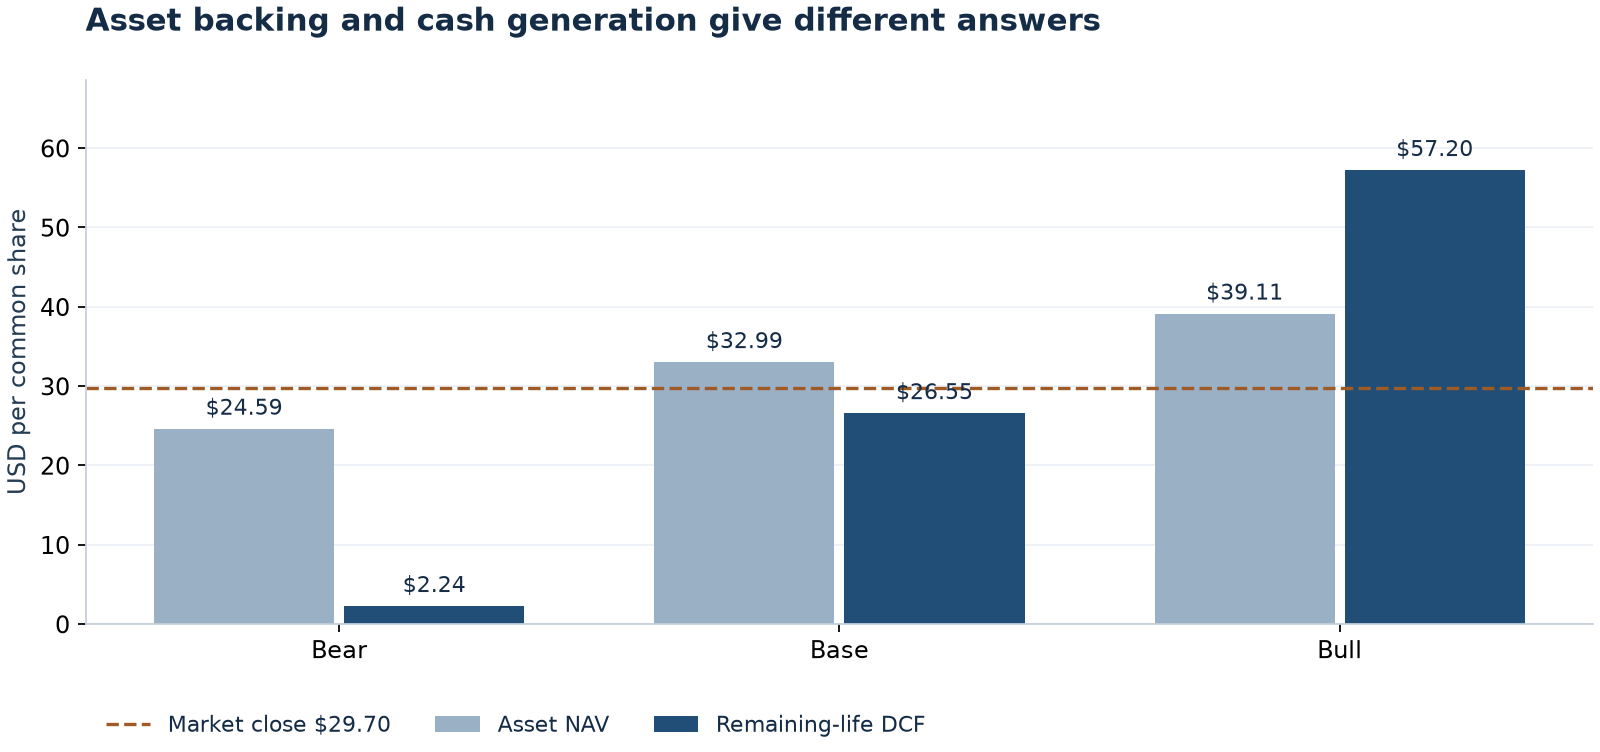

In [4]:
base = cases['base']
display(pd.Series(base.nav, name='USD unless per-share/ratio'))
display(base.forecast[['label','owned','available','revenue','operating','maintenance','newbuild','scrap','delta_wc','ufcf','pv']].head(12).round(2))
display(Image(filename=str(OUT / 'valuation.png')))

The base result puts asset NAV above the $29.70 close, but DCF below it.
The two outputs are not averaged into a price target. NAV reflects dated asset marks;
DCF reflects explicit earnings, costs, overhead and finite lives. The wide scenario range
shows the model's exposure to operating and asset assumptions, not a statistical confidence interval.

The bear case also produces a financing shortfall under the assumed repayment schedule.
This is a prompt to examine refinancing, liquidity and capital actions. It is not a covenant
prediction or a distressed-equity valuation model.

,opening_debt,repayment,closing_debt,interest,ufcf,equity_cash,opening_cash,closing_cash,mincash,headroom
0,949072000.0,0.0,949072000.0,12948982.36,8.051549e+06,-4.897433e+06,5.211420e+08,5.162446e+08,67500000.0,4.487446e+08
1,949072000.0,0.0,949072000.0,14041065.21,1.076439e+08,9.360287e+07,5.162446e+08,6.098474e+08,67500000.0,5.423474e+08
2,949072000.0,141358000.0,807714000.0,13139796.66,1.102580e+08,-4.423977e+07,6.098474e+08,5.656077e+08,67500000.0,4.981077e+08
3,807714000.0,0.0,807714000.0,12215291.18,1.120244e+08,9.980909e+07,5.656077e+08,6.654167e+08,67500000.0,5.979167e+08
4,807714000.0,0.0,807714000.0,12215291.18,1.125837e+08,1.003684e+08,6.654167e+08,7.657852e+08,67500000.0,6.982852e+08
5,807714000.0,0.0,807714000.0,12082516.27,1.119129e+08,9.983043e+07,7.657852e+08,8.656156e+08,67500000.0,7.981156e+08
6,807714000.0,258782000.0,548932000.0,10146968.71,1.124681e+08,-1.564609e+08,8.656156e+08,7.091547e+08,67500000.0,6.416547e+08
7,548932000.0,0.0,548932000.0,8301656.55,1.142711e+08,1.059694e+08,7.091547e+08,8.151241e+08,67500000.0,7.476241e+08
8,548932000.0,0.0,548932000.0,8301656.55,1.148416e+08,1.065400e+08,8.151241e+08,9.216641e+08,67500000.0,8.541641e+08
9,548932000.0,0.0,548932000.0,8121185.75,1.128986e+08,1.047774e+08,9.216641e+08,1.026441e+09,67500000.0,9.589415e+08


,minimum_cash_headroom
bear,-1.504651e+08
base,4.487446e+08
bull,5.925947e+08


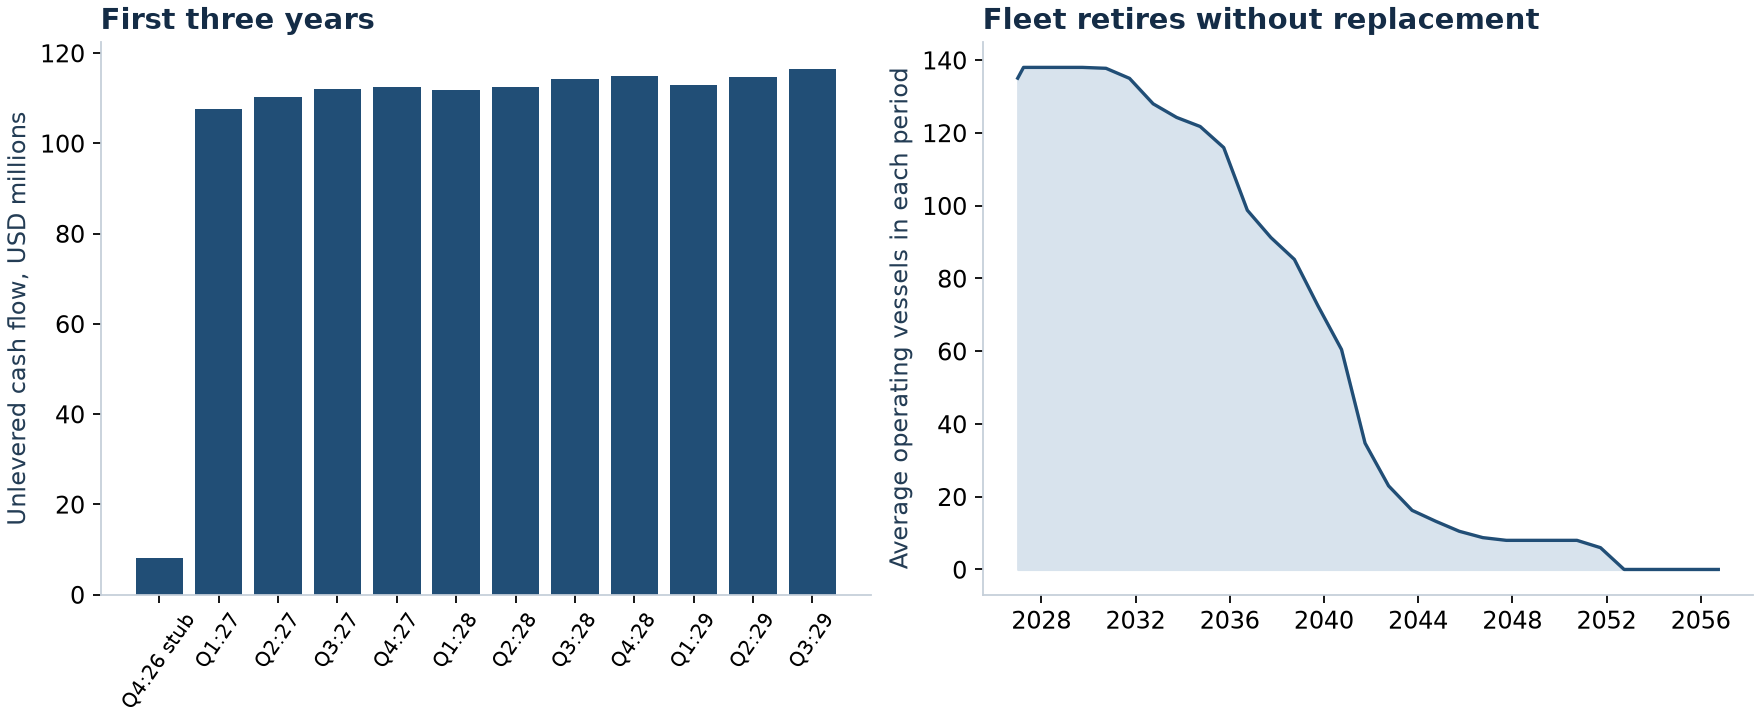

In [5]:
display(base.financing.head(12).round(2))
display(summary[['minimum_cash_headroom']].round(2))
display(Image(filename=str(OUT / 'cash-and-fleet.png')))
assert abs(base.forecast.delta_wc.sum() + company.facts['operating_working_capital']) < 1e-6
assert base.forecast.owned.iloc[-1] == 0
assert abs(base.financing.closing_debt.iloc[-1]) < 1e-6

## 4. Reverse the price

Solve one common multiplier on the open class-rate vector, with all other base assumptions
fixed. A bracketed bisection solver finds the root, then reprices it through the full model.
Working capital changes with earnings. With 100% fixed charter coverage, this parameter
would be unidentifiable rather than having a meaningful implied rate.

In [6]:
root = reverse_valuation(company)
display(root)
assert root['status'] == 'solved'
repriced = value_company(company, rate_multiplier=root['multiplier'])
assert abs(repriced.summary['dcf_per_share'] - company.facts['share_price']) < 1e-8
print(f"Implied open rates: {(root['multiplier'] - 1):.2%} above base under the fixed assumptions.")
display(pd.read_csv(OUT / 'sensitivity.csv').pivot(index='discount_adjustment', columns='rate_multiplier', values='dcf_per_share').round(2))

{'status': 'solved',
 'multiplier': 1.0554745519766584,
 'residual': -9.231502673401337e-09,
 'iterations': 33,
 'bounds': [0, 3]}

Implied open rates: 5.55% above base under the fixed assumptions.


rate_multiplier,0.8,0.9,1.0,1.1,1.2
discount_adjustment,,,,,
-0.02,17.74,24.09,30.43,36.77,43.11
-0.01,16.41,22.41,28.40,34.39,40.38
0.00,15.21,20.88,26.55,32.23,37.90
0.01,14.12,19.50,24.88,30.26,35.64
0.02,13.12,18.24,23.35,28.46,33.58


## 5. Change one assumption at a time

These stresses expose mechanisms. A higher interest rate changes post-financing cash;
it does not change this unlevered DCF unless the discount-rate assumption also changes.
A weaker asset mark changes NAV but does not mechanically overwrite operating cash flows.

In [7]:
stresses = {
    'Base': {},
    'Kamsarmax rate -20%': {'tce_Kamsarmax': company.case()['tce_Kamsarmax'] * .8},
    'Off-hire +5 percentage points': {'offhire': company.case()['offhire'] + .05},
    'Vessel opex +10%': {'opex': company.case()['opex'] * 1.1},
    'Interest +2 percentage points': {'interest': company.case()['interest'] + .02},
    'Asset marks -20%': {'asset_factor': .8},
}
display(pd.DataFrame({name: value_company(company, overrides=overrides).summary
                      for name, overrides in stresses.items()}).T[
    ['nav_per_share','dcf_per_share','next_year_equity_cash','minimum_cash_headroom']].round(2))

,nav_per_share,dcf_per_share,next_year_equity_cash,minimum_cash_headroom
Base,32.99,26.55,2.495406e+08,4.487446e+08
Kamsarmax rate -20%,32.99,23.54,1.997795e+08,4.406143e+08
Off-hire +5 percentage points,32.99,23.57,2.028566e+08,4.407211e+08
Vessel opex +10%,32.99,24.82,2.224560e+08,4.427908e+08
Interest +2 percentage points,32.99,26.55,2.323368e+08,4.444282e+08
Asset marks -20%,25.57,26.55,2.495406e+08,4.487446e+08


## 6. Reconcile the independent implementations

Excel was built first from formulas. This package independently implements the same
economic definitions. The comparison covers summary controls and every modeled cash-flow
and financing period across bear/base/bull. An input fingerprint rejects stale evidence.

This test checks arithmetic consistency. It does not establish that an assumption is true.
Native Excel checks are recorded separately in the verification document.

In [8]:
audit = reconcile(company, OUT / 'excel-calculation-evidence.json')
display({k: v for k, v in audit.items() if k not in ['controls','failures']})
assert audit['status'] == 'pass', audit['failures']
display(pd.DataFrame(audit['controls']).head(12))

{'status': 'pass',
 'input_sha256': '98278536e987c1373aac529d7aa2cc20a45ce8d675b42e177f49c3780acdb328',
 'engine': 'Independent Python vs artifact-tool Excel formula calculation',
 'cells_compared': 3657,
 'max_absolute_difference': 1.9073486328125e-06}

,control,cells,max_abs_difference,tolerance,pass
0,bear / price,1,0.000000e+00,0.0001,True
1,bear / nav_per_share,1,0.000000e+00,0.0001,True
2,bear / price_nav,1,0.000000e+00,0.0001,True
3,bear / enterprise_value,1,0.000000e+00,0.0001,True
4,bear / equity_dcf,1,1.192093e-07,0.0001,True
5,bear / dcf_per_share,1,1.332268e-15,0.0001,True
6,bear / next_year_revenue,1,0.000000e+00,0.0001,True
7,bear / next_year_ufcf,1,5.960464e-08,0.0001,True
8,bear / next_year_equity_cash,1,4.470348e-08,0.0001,True
9,bear / cash flow / owned,39,0.000000e+00,0.0001,True


## 7. What would improve this research?

Update the cash bridge, remaining newbuild payments and vessel marks; reconstruct actual
charter coverage; replace approximate maturity dates and smoothed docking budgets with
reviewed schedules. Normalize Genco and Safe Bulkers before making relative-value claims.
Historical validation requires genuine as-of forecasts and later operating disclosures.

The current project supports additional dry-bulk stocks through independent data folders.
Use `shipping-equity init-company` and follow `docs/ADDING_COMPANIES.md`. Do not copy Star Bulk
facts into another ticker. Tankers, containers and LNG carriers require reviewed segment economics.
The separate `tests/fixtures/SYNTH` package is entirely invented and only tests arithmetic.